# 03 — Feature Engineering

**Project:** Sales Demand Forecasting & Anomaly Detection
**Dataset:** Corporación Favorita store sales (Kaggle) — daily store-level sales.

This notebook builds every feature the forecasting models (Phases 4–5) and anomaly
detector (Phase 6) will consume. Every feature is justified by an EDA finding from
notebook 02 or by a well-known time-series modeling argument.

**What we do here:**

| Section | What | Why |
|---|---|---|
| A | Base target series | Aggregate to network, store-type, and case-study levels |
| B | Date features | Capture weekly/monthly/yearly rhythm (EDA Q2) |
| C | Lagged & rolling features | Let the model “see” recent history — with `shift()` to prevent leakage |
| D | Exogenous inputs | Features known in advance (promo, holidays, day-of-week) |
| E | Promo context | Cross-store promo intensity for aggregate series |
| F | Temporal split | Chronological train / validation / test — never shuffle |
| G | Leakage check | Verify no future information leaks into past rows |
| H | Save outputs | CSV files for Phases 4–6 and the dashboard |

> **Interview focus:** feature engineering for time series is about *one discipline*:
> **never let the future leak into the past.** Every lag, every rolling stat, every
> split boundary must respect chronological order. We demonstrate this explicitly.

## Setup — imports and data reload

We reload the cleaned data from Phase 2. The `assert` guard ensures the notebook
is run from the `notebooks/` folder (a convention established in Phase 1).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 100
sns.set_theme(style="whitegrid")

# — paths (absolute to avoid cd-dependency — lesson from Phase 2) ──
ROOT = Path(r"E:\\Data Science\\Sales Demand Forecasting and Anomaly Detection")
RAW  = ROOT / "data" / "raw"
PROC = ROOT / "data" / "processed"
PROC.mkdir(parents=True, exist_ok=True)

assert (PROC / "train_clean.csv").exists(), \
    "Run 02_eda.ipynb first to produce the cleaned data."

train = pd.read_csv(PROC / "train_clean.csv", parse_dates=["Date"])
store = pd.read_csv(PROC / "store_clean.csv")

print(f"train: {train.shape} | store: {store.shape}")
print(f"Date range: {train['Date'].min().date()} \u2192 {train['Date'].max().date()}")
print(f"Stores: {train['Store'].nunique()} | Days: {train['Date'].nunique()}")

train: (1017209, 9) | store: (1115, 11)
Date range: 2013-01-01 → 2015-07-31
Stores: 1115 | Days: 942


---

# Part A — Base target series

Before engineering features, we need to decide **what we are forecasting**.
The dataset has ~1M store-day rows, but we are *not* building 1,115 separate
store-level models. Instead, we work at three levels of aggregation:

| Level | Rows (approx) | Purpose |
|---|---|---|
| **Network daily** | 942 | Overall business view; the headline forecast |
| **Store-type daily** (4 types) | 942 × 4 | Understanding how different segments behave |
| **Case-study stores** (~5 stores) | 942 × 5 | Deep-dive; shows the model works at store level too |

### Why aggregate to daily totals?

- A single network-level series is easy to visualize and explain.
- Store-type series let us check whether the model captures type-specific patterns
  (recall EDA Q3: types differ in *level* but share the *weekday pattern*).
- Case-study stores (top 5 by lifetime sales, complete series only) demonstrate
  that the approach works for individual stores too — great for the resume.

### How we aggregate

- `Sales`: sum across all stores (or stores of a given type) per day.
- `Open`: count of stores that were open (capacity proxy).
- `Promo`: share of open stores running a promo (0 to 1) — a richer signal than
  a simple boolean.
- `StateHoliday` / `SchoolHoliday`: keep as-is (same for all stores on a given date).

In [2]:
# ── A1. Network daily total ──────────────────────────────
open_mask = train["Open"] == 1

# Daily aggregation: sum sales, count open stores, compute promo share
network = (
    train
    .groupby("Date")
    .agg(
        sales=("Sales", "sum"),
        n_open=("Open", "sum"),
    )
    .reset_index()
)

# Promo share among open stores (only meaningful when stores are open)
promo_daily = (
    train[open_mask]
    .groupby("Date")["Promo"]
    .mean()
    .rename("promo_share")
)
network = network.merge(promo_daily, on="Date", how="left").fillna(0)

# Holiday flags (same for all stores on a given date)
hol_daily = (
    train
    .assign(is_holiday=lambda d: d["StateHoliday"].ne("none").astype(int))
    .groupby("Date")
    .agg(
        any_holiday=("is_holiday", "max"),
        state_holiday=("StateHoliday", "first"),
    )
)
school_daily = train.groupby("Date")["SchoolHoliday"].max().rename("any_school_holiday")
network = network.merge(hol_daily, on="Date").merge(school_daily, on="Date")

print("Network daily series:", network.shape)
print(network.head(3).to_string(index=False))
print(f"\nDate range: {network['Date'].min().date()} \u2192 {network['Date'].max().date()}")

Network daily series: (942, 7)
      Date   sales  n_open  promo_share  any_holiday state_holiday  any_school_holiday
2013-01-01   97235      17          0.0            1             a                   1
2013-01-02 6949829    1111          0.0            0          none                   1
2013-01-03 6347820    1109          0.0            0          none                   1

Date range: 2013-01-01 → 2015-07-31


In [3]:
# ── A2. Store-type daily series ──────────────────────────────
# Merge store type into the train data
train_typed = train.merge(store[["Store", "StoreType"]], on="Store", how="left")

type_series = []
for stype in sorted(train_typed["StoreType"].unique()):
    sub = train_typed[train_typed["StoreType"] == stype]
    sub_open = sub[sub["Open"] == 1]

    daily = sub.groupby("Date").agg(
        sales=("Sales", "sum"),
        n_open=("Open", "sum"),
    ).reset_index()

    promo = sub_open.groupby("Date")["Promo"].mean().rename("promo_share")
    daily = daily.merge(promo, on="Date", how="left").fillna(0)

    daily["store_type"] = stype
    type_series.append(daily)

type_df = pd.concat(type_series, ignore_index=True)
print("Store-type series:", type_df.shape)
print(type_df.groupby("store_type")[["sales", "n_open"]].describe().round(0))

Store-type series: (3768, 5)
            sales                                                                            n_open                                    \
            count       mean        std      min        25%        50%        75%        max  count   mean    std   min    25%    50%   
store_type                                                                                                                              
a           942.0  3360228.0  1741426.0      0.0  2994007.0  3563650.0  4459142.0  8511488.0  942.0  485.0  218.0   0.0  518.0  600.0   
b           942.0   169035.0    29009.0  94328.0   147792.0   167678.0   188296.0   254479.0  942.0   17.0    1.0  14.0   16.0   17.0   
c           942.0   831445.0   425547.0      0.0   750418.0   916580.0  1075648.0  2086808.0  942.0  120.0   54.0   0.0  133.0  147.0   
d           942.0  1874090.0   981047.0      0.0  1627814.0  2034642.0  2481087.0  4777323.0  942.0  275.0  127.0   0.0  267.0  347.0   

           

In [4]:
# ── A3. Case-study stores (top 5, complete series only) ────────────────
# "Complete series" = every day in the panel (no gaps)
panel_days = train["Date"].nunique()  # 942

store_days = train.groupby("Store")["Date"].nunique()
complete_stores = store_days[store_days == panel_days].index

top_by_sales = (
    train[train["Store"].isin(complete_stores)]
    .groupby("Store")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)
print("Case-study stores (top 5, complete series):")
for sid, total in top_by_sales.items():
    print(f"  Store {sid:>4d}: ${total/1e6:.2f}M lifetime sales")

case_ids = list(top_by_sales.index)
case_series = train[train["Store"].isin(case_ids)].copy()
case_series = case_series.merge(store[["Store", "StoreType"]], on="Store", how="left")
print(f"\nCase-study rows: {case_series.shape[0]} ({len(case_ids)} stores × {panel_days} days)")

Case-study stores (top 5, complete series):
  Store  262: $19.52M lifetime sales
  Store  817: $17.06M lifetime sales
  Store  562: $16.93M lifetime sales
  Store 1114: $16.20M lifetime sales
  Store  251: $14.90M lifetime sales

Case-study rows: 4710 (5 stores × 942 days)


### Summary — Part A

| Series | Rows | What we will forecast |
|---|---|---|
| `network` | 942 | Total daily sales across all stores |
| `type_df` | 3,768 | Daily sales per store type (4 types) |
| `case_series` | 4,710 | Daily sales per case-study store (5 stores) |

All three share the same date axis. Feature creation (Parts B–E) operates on
these aggregated series — we build features that work for *any* daily sales
series, then apply them to each.

---

# Part B — Date features

Date-derived features capture **temporal rhythm** — the patterns we saw in EDA Q2
(weekly sawtooth, monthly bumps) and Q3 (year-over-year structure). These features
are always valid because the calendar is known in advance.

| Feature | Source | Justification |
|---|---|---|
| `day_of_week` | `Date.dt.dayofweek` (0=Mon) | EDA Q2: strong weekly seasonality |
| `month` | `Date.dt.month` | EDA Q2: mid/end-of-month salary bumps |
| `week_of_year` | `Date.dt.isocalendar().week` | Captures intra-year position |
| `year` | `Date.dt.year` | Trend / growth structure |
| `is_weekend` | day_of_week ≥ 5 | EDA Q2: Saturday/Sunday spike |
| `day_of_month` | `Date.dt.day` | Payday effects (1st, 15th, last day) |
| `is_month_start` | `Date.dt.is_month_start` | Beginning-of-month behavior |
| `is_month_end` | `Date.dt.is_month_end` | End-of-month salary bumps |
| Cyclical sin/cos | sin/cos of day-of-week and month | Preserves circular nature of calendar |

> **Why not use Date directly?** Models need numeric or categorical inputs, not
> datetime objects. We decompose the date into interpretable features.

> **Why cyclical encoding?** Day 6 (Sunday) is close to day 0 (Monday), but a linear
> encoding treats them as far apart. Sin/cos preserves the circular structure.

In [5]:
def add_date_features(df, sales_col="sales", date_col="Date"):
    """Add calendar features to a daily series. Works on ANY daily aggregation."""
    df = df.copy()
    dt = df[date_col]

    # — Core calendar ——————————————————————————————
    df["day_of_week"]    = dt.dt.dayofweek          # 0=Mon, 6=Sun
    df["month"]          = dt.dt.month               # 1–12
    df["week_of_year"]   = dt.dt.isocalendar().week.astype(int)
    df["year"]           = dt.dt.year
    df["is_weekend"]     = (df["day_of_week"] >= 5).astype(int)
    df["day_of_month"]   = dt.dt.day                 # 1–31
    df["is_month_start"] = dt.dt.is_month_start.astype(int)
    df["is_month_end"]   = dt.dt.is_month_end.astype(int)

    # — Cyclical encoding (optional — helps some models) ——————————
    # day_of_week and month are cyclical: day 6 (Sun) is close to day 0 (Mon).
    # Sine/cosine encoding preserves this circular structure.
    df["dow_sin"] = np.sin(2 * np.pi * df["day_of_week"] / 7)
    df["dow_cos"] = np.cos(2 * np.pi * df["day_of_week"] / 7)
    df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
    df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)

    return df

# Apply to network series
network = add_date_features(network)
print("Network features after date engineering:", network.shape[1], "columns")
print("New columns:", [c for c in network.columns if c not in
      ["Date", "sales", "n_open", "promo_share", "any_holiday",
       "state_holiday", "any_school_holiday"]])

Network features after date engineering: 19 columns
New columns: ['day_of_week', 'month', 'week_of_year', 'year', 'is_weekend', 'day_of_month', 'is_month_start', 'is_month_end', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos']


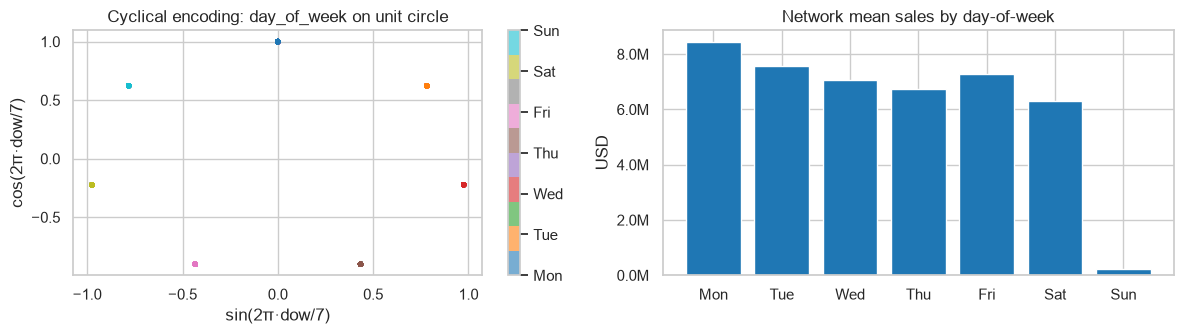

In [6]:
# Quick visual check — do the cyclical encodings make sense?
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

# Sine/cosine scatter: each day-of-week maps to a point on the unit circle
axes[0].scatter(network["dow_sin"], network["dow_cos"],
                c=network["day_of_week"], cmap="tab10", s=8, alpha=0.6)
axes[0].set_title("Cyclical encoding: day_of_week on unit circle")
axes[0].set_xlabel("sin(2π·dow/7)")
axes[0].set_ylabel("cos(2π·dow/7)")
cbar = plt.colorbar(axes[0].collections[0], ax=axes[0], ticks=range(7))
cbar.ax.set_yticklabels(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"])

# Mean sales by day-of-week to confirm weekly pattern
dow_means = network.groupby("day_of_week")["sales"].mean()
axes[1].bar(range(7), dow_means.values, color="#1f77b4")
axes[1].set_xticks(range(7))
axes[1].set_xticklabels(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"])
axes[1].set_title("Network mean sales by day-of-week")
axes[1].set_ylabel("USD")
axes[1].yaxis.set_major_formatter(lambda x, _: f"{x/1e6:.1f}M")

plt.tight_layout()
plt.show()

---

# Part C — Lagged and rolling features

This is the **most important section for avoiding data leakage** — and the one
interviewers love to ask about.

### What is a lagged feature?

A lagged feature is simply **the value of the target variable at a previous time step**.
For example, `sales_lag_7` on a Tuesday is the sales from *last Tuesday*. This lets
the model see the recent trajectory of the series.

### What is a rolling feature?

A rolling feature computes a **summary statistic over a sliding window** of past values.
For example, `rolling_mean_7` is the average of the last 7 days of sales.

### The leakage trap

> **If you accidentally include the current day’s sales in a rolling window, you are
> letting the model “cheat” by peeking at the answer.**

The fix: **always `shift()` before computing rolling statistics.**

    # CORRECT (no leakage):
    df["rolling_mean_7"] = df["sales"].shift(1).rolling(7).mean()

    # WRONG (leaks future info):
    df["rolling_mean_7"] = df["sales"].rolling(7).mean()  # includes today!

The `shift(1)` ensures the window only sees days *before* the current row.

### Lag windows we use

| Lag | What it captures |
|---|---|
| 1 | Yesterday’s sales (autocorrelation) |
| 2 | Day-before-yesterday |
| 7 | Last week’s sales (weekly seasonality) |
| 14 | Two weeks ago |
| 28 | Last month (if data allows) |

### Rolling windows

| Window | What it captures |
|---|---|
| 7-day mean | Recent weekly average |
| 28-day mean | Recent monthly average |
| 7-day std | Recent volatility (how “stable” is sales) |

In [7]:
def add_lag_features(df, sales_col="sales"):
    """
    Create lagged and rolling features using shift() to prevent leakage.

    CRITICAL: shift(1) means "use only values from PREVIOUS rows".
    The rolling window then operates on these shifted values, so the current
    day’s sales never enters any feature.
    """
    df = df.copy()
    s = df[sales_col]

    # — Lagged sales ——————————————————————————————————
    # Each lag = “what was sales N days ago?”
    for lag in [1, 2, 7, 14, 28]:
        df[f"sales_lag_{lag}"] = s.shift(lag)

    # — Rolling means ————————————————————————————————
    # shift(1) first: window sees days BEFORE today only
    for window in [7, 28]:
        df[f"rolling_mean_{window}"] = s.shift(1).rolling(window).mean()

    # — Rolling standard deviation ——————————————————————
    # Volatility: how much does sales vary in the recent window?
    df["rolling_std_7"] = s.shift(1).rolling(7).std()

    # — Rolling median (robust alternative to mean) —————————————
    df["rolling_median_7"] = s.shift(1).rolling(7).median()

    # — Lagged promo share (for aggregate series) ————————————
    if "promo_share" in df.columns:
        for lag in [1, 7]:
            df[f"promo_lag_{lag}"] = df["promo_share"].shift(lag)

    return df

# Apply to network series
network = add_lag_features(network)

# Show the first rows to see how NaNs appear at the start (expected!)
print("Columns after lag engineering:", network.shape[1])
print()
print("First 5 rows (note NaNs in lag/rolling columns — expected):")
lag_cols = [c for c in network.columns if "lag" in c or "rolling" in c]
print(network[["Date", "sales"] + lag_cols].head(5).to_string(index=False))

Columns after lag engineering: 30

First 5 rows (note NaNs in lag/rolling columns — expected):
      Date   sales  sales_lag_1  sales_lag_2  sales_lag_7  sales_lag_14  sales_lag_28  rolling_mean_7  rolling_mean_28  rolling_std_7  rolling_median_7  promo_lag_1  promo_lag_7
2013-01-01   97235          NaN          NaN          NaN           NaN           NaN             NaN              NaN            NaN               NaN          NaN          NaN
2013-01-02 6949829      97235.0          NaN          NaN           NaN           NaN             NaN              NaN            NaN               NaN          0.0          NaN
2013-01-03 6347820    6949829.0      97235.0          NaN           NaN           NaN             NaN              NaN            NaN               NaN          0.0          NaN
2013-01-04 6638954    6347820.0    6949829.0          NaN           NaN           NaN             NaN              NaN            NaN               NaN          0.0          NaN
2013-01-05 5951

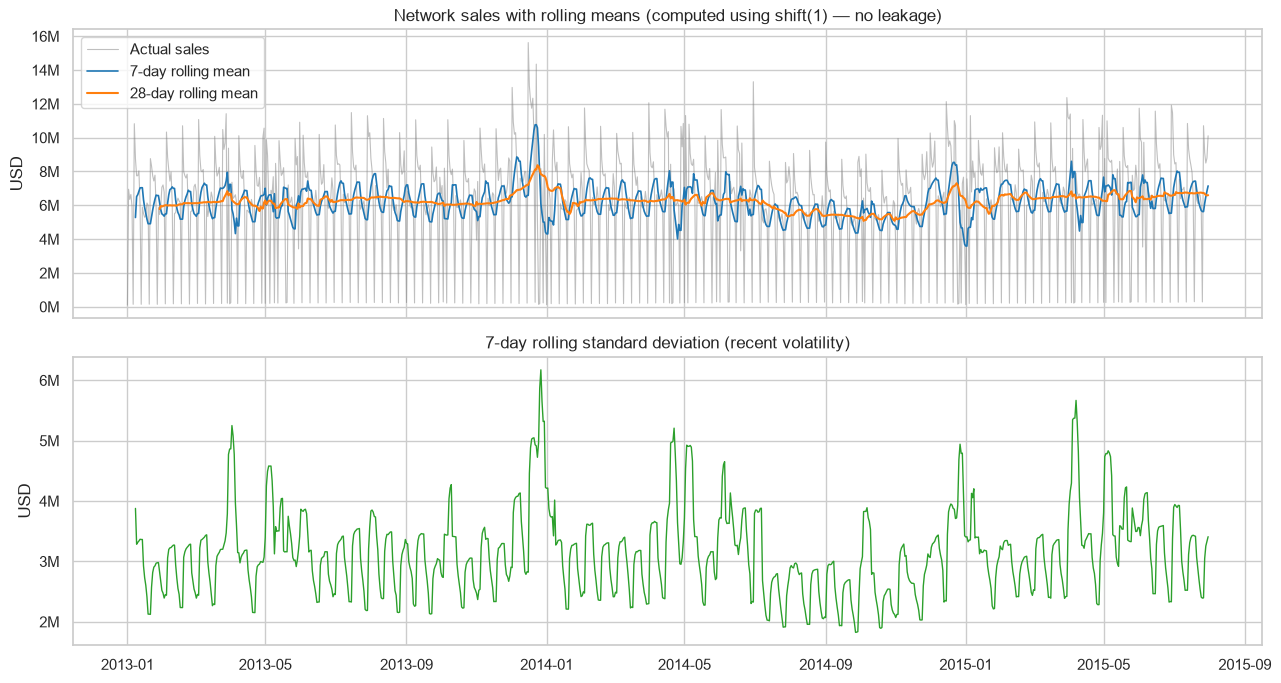

In [8]:
# Visualize: how do the rolling features relate to actual sales?
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

# Top: actual sales vs rolling means
axes[0].plot(network["Date"], network["sales"], color="grey", lw=0.8, alpha=0.5, label="Actual sales")
axes[0].plot(network["Date"], network["rolling_mean_7"], color="#1f77b4", lw=1.2, label="7-day rolling mean")
axes[0].plot(network["Date"], network["rolling_mean_28"], color="#ff7f0e", lw=1.5, label="28-day rolling mean")
axes[0].set_title("Network sales with rolling means (computed using shift(1) — no leakage)")
axes[0].set_ylabel("USD")
axes[0].legend()
axes[0].yaxis.set_major_formatter(lambda x, _: f"{x/1e6:.0f}M")

# Bottom: rolling std (volatility)
axes[1].plot(network["Date"], network["rolling_std_7"], color="#2ca02c", lw=1)
axes[1].set_title("7-day rolling standard deviation (recent volatility)")
axes[1].set_ylabel("USD")
axes[1].yaxis.set_major_formatter(lambda x, _: f"{x/1e6:.0f}M")

plt.tight_layout()
plt.show()

---

# Part D — Exogenous input features

**Exogenous features** are inputs that are *not* the target variable but help
predict it. For forecasting, the key requirement is that these features must be
**known or knowable in advance** — we cannot use a feature that only becomes
available after the prediction date.

### Feature validity for forecasting

| Feature | Known in advance? | Why it helps |
|---|---|---|
| `day_of_week` | Yes (calendar) | Weekly seasonality (EDA Q2) |
| `month` | Yes (calendar) | Monthly patterns |
| `is_weekend` | Yes (calendar) | Weekend effect (EDA Q2) |
| `is_month_start/end` | Yes (calendar) | Payday bumps (EDA Q2) |
| `school_holiday` | Yes (published calendar) | School closures affect foot traffic |
| `Promo` | Partially | Promotions are planned, but exact schedule may not be public |
| `StateHoliday` | Yes (government calendar) | Holidays are known (EDA Q6) |
| `n_open` | No | We do not know how many stores will open tomorrow |
| `Customers` | No | Unknown in the future (EDA Q8) |

> **Note on Promo:** In practice, store promotions are planned weeks ahead.
> For this project, we treat `Promo` as known-in-advance (a reasonable simplification).

In [9]:
def add_exogenous_features(df):
    """
    Add exogenous (external) features that are known or knowable in advance.

    For the network-level series, we already have: promo_share, any_holiday,
    state_holiday, any_school_holiday (from Part A).

    This function adds interaction features that capture combined effects.
    """
    df = df.copy()

    # — Promo x weekend interaction —————————————————————————————————
    # Do promos on weekends have a different effect than on weekdays?
    if "promo_share" in df.columns and "is_weekend" in df.columns:
        df["promo_x_weekend"] = df["promo_share"] * df["is_weekend"]

    # — Holiday x promo interaction ———————————————————————————
    if "any_holiday" in df.columns and "promo_share" in df.columns:
        df["holiday_x_promo"] = df["any_holiday"] * df["promo_share"]

    # — Days since last holiday (recency feature) ———————————————
    if "any_holiday" in df.columns:
        hol = df["any_holiday"].values
        days_since = np.zeros(len(hol), dtype=int)
        last_holiday = -999  # start far in the past
        for i in range(len(hol)):
            if hol[i]:
                last_holiday = i
            days_since[i] = i - last_holiday
        df["days_since_holiday"] = days_since

    # — Is it a “special” day? (holiday + weekend + month boundary) ———
    df["n_special_flags"] = (
        df.get("is_weekend", 0) +
        df.get("any_holiday", 0) +
        df.get("is_month_start", 0) +
        df.get("is_month_end", 0)
    )

    return df

network = add_exogenous_features(network)
print("Network features after exogenous engineering:", network.shape[1], "columns")
print("New interaction/context features:",
      [c for c in network.columns if "x_" in c or "days_since" in c or "special" in c])

Network features after exogenous engineering: 34 columns
New interaction/context features: ['promo_x_weekend', 'holiday_x_promo', 'days_since_holiday', 'n_special_flags']


---

# Part E — Promo context features

For the **network-level** series, we already computed `promo_share` (fraction of
open stores running a promo). Here we add richer context:

- **Promo momentum:** Is promo intensity increasing or decreasing?
- **Promo streak:** How many consecutive days has promo share been above average?
- **Lagged promo share** (already added in Part C for the network series).

These features help the model understand not just “is there a promo today?” but
“how does today’s promo context compare to recent history?” — a subtler signal.

In [10]:
def add_promo_context(df):
    """
    Richer promo context features for aggregate series.

    These go beyond simple promo_share by capturing trends and streaks
    in promotional activity — which can signal upcoming demand shifts.
    """
    df = df.copy()

    if "promo_share" not in df.columns:
        return df

    ps = df["promo_share"]

    # — Promo momentum: change vs 7 days ago ——————————————————
    df["promo_momentum_7"] = ps - ps.shift(7)

    # — Promo streak: consecutive days above median ———————————————
    median_promo = ps.median()
    above = (ps > median_promo).astype(int)
    streak = np.zeros(len(above), dtype=int)
    for i in range(len(above)):
        if above.iloc[i]:
            streak[i] = streak[i - 1] + 1 if i > 0 else 1
        else:
            streak[i] = 0
    df["promo_streak"] = streak

    # — Rolling promo share (7-day average of promo intensity) —————————
    df["promo_rolling_7"] = ps.shift(1).rolling(7).mean()

    return df

network = add_promo_context(network)
print("Network features after promo context:", network.shape[1], "columns")
promo_ctx = [c for c in network.columns if "promo" in c]
print("Promo-related columns:", promo_ctx)

Network features after promo context: 37 columns
Promo-related columns: ['promo_share', 'promo_lag_1', 'promo_lag_7', 'promo_x_weekend', 'holiday_x_promo', 'promo_momentum_7', 'promo_streak', 'promo_rolling_7']


---

# Part F — Temporal (chronological) split

### Why not random split?

In time series, **random splits leak future information.** If a model trains on
January 15 and tests on January 10, it has “seen the future” — the January 15
value occurred *after* January 10. The model appears accurate but will fail in
production.

**Chronological split** respects the arrow of time:

    |<--- Training (earliest) --->|<-- Validation -->|<-- Test (latest) -->|
    2013-01-01                2015-06-30       2015-07-01          2015-07-31

### Split boundaries

| Split | Date range | Days | Purpose |
|---|---|---|---|
| **Train** | 2013-01-01 to 2015-06-30 | 912 | Model learns patterns |
| **Validation** | 2015-07-01 to 2015-07-15 | 15 | Tune hyperparameters, compare models |
| **Test** | 2015-07-16 to 2015-07-31 | 16 | Final honest evaluation |

### Why these sizes?

- The dataset covers ~31 months (942 days). We reserve the **last month** for
  evaluation — enough data to see weekly patterns.
- 15 days validation + 16 days test = 1 month total.
- The validation set lets us compare models (SARIMA vs tree-based) before the
  final test set gives us the “real” performance number.

In [11]:
# — Define split boundaries —————————————————————————————————————
SPLIT_VALID_START = pd.Timestamp("2015-07-01")
SPLIT_TEST_START  = pd.Timestamp("2015-07-16")
DATA_END          = train["Date"].max()

print(f"Dataset ends:      {DATA_END.date()}")
print(f"Validation starts: {SPLIT_VALID_START.date()}")
print(f"Test starts:       {SPLIT_TEST_START.date()}")
print()

def temporal_split(df, date_col="Date"):
    """
    Split a DataFrame chronologically into train / validation / test.

    Returns three DataFrames. The split is by DATE, never by row index.
    """
    mask_train = df[date_col] < SPLIT_VALID_START
    mask_valid = (df[date_col] >= SPLIT_VALID_START) & (df[date_col] < SPLIT_TEST_START)
    mask_test  = df[date_col] >= SPLIT_TEST_START

    train_df = df[mask_train].copy()
    valid_df = df[mask_valid].copy()
    test_df  = df[mask_test].copy()

    return train_df, valid_df, test_df

# Split the network series
net_train, net_valid, net_test = temporal_split(network)

print("Network series split:")
print(f"  Train:      {net_train.shape[0]:>4d} rows  "
      f"({net_train['Date'].min().date()} \u2192 {net_train['Date'].max().date()})")
print(f"  Validation: {net_valid.shape[0]:>4d} rows  "
      f"({net_valid['Date'].min().date()} \u2192 {net_valid['Date'].max().date()})")
print(f"  Test:       {net_test.shape[0]:>4d} rows  "
      f"({net_test['Date'].min().date()} \u2192 {net_test['Date'].max().date()})")

Dataset ends:      2015-07-31
Validation starts: 2015-07-01
Test starts:       2015-07-16

Network series split:
  Train:       911 rows  (2013-01-01 → 2015-06-30)
  Validation:   15 rows  (2015-07-01 → 2015-07-15)
  Test:         16 rows  (2015-07-16 → 2015-07-31)


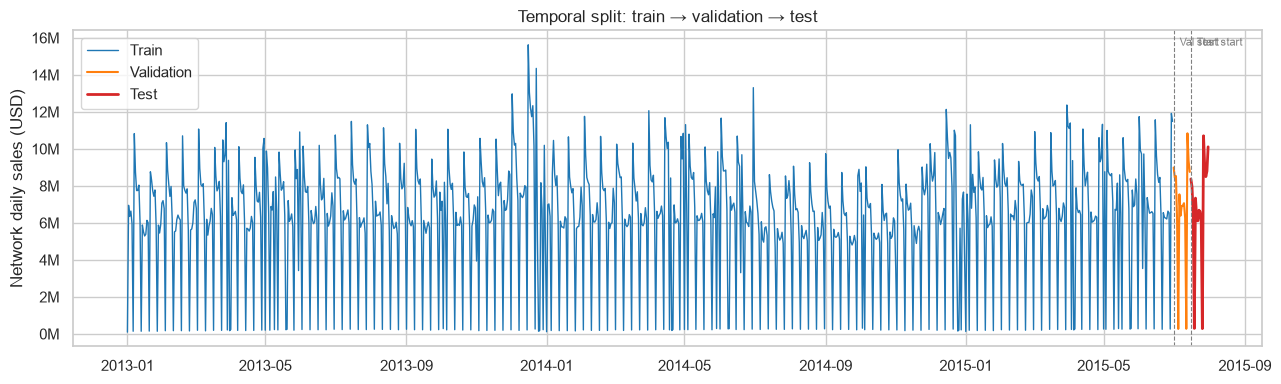

In [12]:
# — Visualize the split ——————————————————————————————————————
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(net_train["Date"], net_train["sales"], color="#1f77b4", lw=1, label="Train")
ax.plot(net_valid["Date"], net_valid["sales"], color="#ff7f0e", lw=1.5, label="Validation")
ax.plot(net_test["Date"],  net_test["sales"],  color="#d62728", lw=2, label="Test")

# Draw split lines
ax.axvline(SPLIT_VALID_START, color="grey", ls="--", lw=0.8)
ax.axvline(SPLIT_TEST_START,  color="grey", ls="--", lw=0.8)
ax.text(SPLIT_VALID_START, ax.get_ylim()[1]*0.95, "  Val start", fontsize=8, color="grey")
ax.text(SPLIT_TEST_START,  ax.get_ylim()[1]*0.95, "  Test start", fontsize=8, color="grey")

ax.set_title("Temporal split: train \u2192 validation \u2192 test")
ax.set_ylabel("Network daily sales (USD)")
ax.yaxis.set_major_formatter(lambda x, _: f"{x/1e6:.0f}M")
ax.legend()
plt.tight_layout()
plt.show()

In [13]:
# — Verify: no temporal overlap ———————————————————————————————
last_train  = net_train["Date"].max()
first_valid = net_valid["Date"].min()
first_test  = net_test["Date"].min()

assert last_train < first_valid, "Train and validation overlap!"
assert net_valid["Date"].max() < first_test, "Validation and test overlap!"
assert net_test["Date"].max() <= DATA_END, "Test extends beyond data!"

print("Temporal split verified \u2014 no overlap between splits.")
print(f"   Train ends {last_train.date()}, Validation starts {first_valid.date()}, "
      f"Test starts {first_test.date()}")

Temporal split verified — no overlap between splits.
   Train ends 2015-06-30, Validation starts 2015-07-01, Test starts 2015-07-16


---

# Part G — Leakage check

**Data leakage** is the #1 reason time-series models look great in development
but fail in production. We run a systematic check to make sure none of our
features accidentally peek into the future.

### Three types of leakage we guard against

| Type | How it happens | Our defense |
|---|---|---|
| **Target leakage** | Using a feature derived from the target (e.g., `Customers`) | We excluded `Customers` entirely |
| **Temporal leakage** | Using future values of a time-dependent feature | All lags use `shift(N)`; rolling windows use `shift(1)` before `.rolling()` |
| **Information leakage at split** | Training on future data, testing on past data | Chronological split (Part F); no shuffling |

### The key test

For every lagged/rolling feature, we verify that **row N’s feature value depends
only on rows 1 through N-1** (never on row N or later). We do this by checking
that the feature value matches what you would get by manually computing from past rows.

In [14]:
# — G1. Verify lag shift correctness ————————————————————————————————
print("=" * 60)
print("LEAKAGE CHECK: Lag features")
print("=" * 60)

sample_row = 50  # pick an arbitrary row
date_at_sample = network.loc[sample_row, "Date"]
sales_at_sample = network.loc[sample_row, "sales"]

print(f"\nRow {sample_row}: Date = {date_at_sample.date()}, Sales = ${sales_at_sample:,.0f}")
print()

for lag in [1, 2, 7, 14, 28]:
    feature_val = network.loc[sample_row, f"sales_lag_{lag}"]

    # Manual check: look up the sales value from lag days before
    target_date = date_at_sample - pd.Timedelta(days=lag)
    manual_val = network.loc[network["Date"] == target_date, "sales"].values
    manual_val = manual_val[0] if len(manual_val) > 0 else np.nan

    match = (feature_val == manual_val) or (pd.isna(feature_val) and pd.isna(manual_val))
    status = "PASS" if match else "FAIL — LEAKAGE"
    print(f"  sales_lag_{lag:>2d}: feature={feature_val:>12,.0f}  "
          f"manual({target_date.date()})={manual_val:>12,.0f}  {status}")

LEAKAGE CHECK: Lag features

Row 50: Date = 2013-02-20, Sales = $7,759,768

  sales_lag_ 1: feature=   7,988,672  manual(2013-02-19)=   7,988,672  PASS
  sales_lag_ 2: feature=  10,703,641  manual(2013-02-18)=  10,703,641  PASS
  sales_lag_ 7: feature=   6,175,147  manual(2013-02-13)=   6,175,147  PASS
  sales_lag_14: feature=   8,094,803  manual(2013-02-06)=   8,094,803  PASS
  sales_lag_28: feature=   7,746,563  manual(2013-01-23)=   7,746,563  PASS


In [15]:
# — G2. Verify rolling mean correctness ————————————————————————————
print("=" * 60)
print("LEAKAGE CHECK: Rolling features")
print("=" * 60)

sample_row = 60
date_at_sample = network.loc[sample_row, "Date"]

print(f"\nRow {sample_row}: Date = {date_at_sample.date()}")
print()

for window in [7, 28]:
    feature_val = network.loc[sample_row, f"rolling_mean_{window}"]

    # Manual check: average of the window days BEFORE the current date
    start_date = date_at_sample - pd.Timedelta(days=window)
    end_date   = date_at_sample - pd.Timedelta(days=1)
    window_data = network.loc[
        (network["Date"] >= start_date) & (network["Date"] <= end_date), "sales"
    ]
    manual_val = window_data.mean() if len(window_data) == window else np.nan

    match = (abs(feature_val - manual_val) < 0.01) if not pd.isna(feature_val) else pd.isna(manual_val)
    status = "PASS" if match else "FAIL — LEAKAGE"
    print(f"  rolling_mean_{window:>2d}: feature={feature_val:>12,.0f}  "
          f"manual={manual_val:>12,.0f}  {status}")

print()
print("If any check shows FAIL, the feature was computed incorrectly (leaks future info).")

LEAKAGE CHECK: Rolling features

Row 60: Date = 2013-03-02

  rolling_mean_ 7: feature=   5,349,330  manual=   5,349,330  PASS
  rolling_mean_28: feature=   6,127,696  manual=   6,127,696  PASS

If any check shows FAIL, the feature was computed incorrectly (leaks future info).


In [16]:
# — G3. Verify split boundaries do not leak ————————————————————
print("=" * 60)
print("LEAKAGE CHECK: Temporal split")
print("=" * 60)

# The latest date in training should be BEFORE the earliest date in validation
train_max  = net_train["Date"].max()
valid_min  = net_valid["Date"].min()
valid_max  = net_valid["Date"].max()
test_min   = net_test["Date"].min()

print(f"\n  Train max date:  {train_max.date()}")
print(f"  Valid min date:  {valid_min.date()}")
print(f"  Valid max date:  {valid_max.date()}")
print(f"  Test min date:   {test_min.date()}")
print()

# Check that lag features for validation rows only use training data
val_row = net_valid.iloc[0]
val_date = val_row["Date"]
print(f"  First validation row: {val_date.date()}")
train_label = "(train)"
leak_label = "(LEAKS!)"
d1 = val_date - pd.Timedelta(days=1)
d7 = val_date - pd.Timedelta(days=7)
d28 = val_date - pd.Timedelta(days=28)
print(f"    sales_lag_1  uses data from {d1.date()} {train_label if d1 <= train_max else leak_label}")
print(f"    sales_lag_7  uses data from {d7.date()} {train_label if d7 <= train_max else leak_label}")
print(f"    sales_lag_28 uses data from {d28.date()} {train_label if d28 <= train_max else leak_label}")

LEAKAGE CHECK: Temporal split

  Train max date:  2015-06-30
  Valid min date:  2015-07-01
  Valid max date:  2015-07-15
  Test min date:   2015-07-16

  First validation row: 2015-07-01
    sales_lag_1  uses data from 2015-06-30 (train)
    sales_lag_7  uses data from 2015-06-24 (train)
    sales_lag_28 uses data from 2015-06-03 (train)


In [17]:
# — G4. Check for NaN patterns in lag features —————————————————
print("=" * 60)
print("LEAKAGE CHECK: NaN counts by split")
print("=" * 60)

lag_cols = [c for c in network.columns if "lag" in c or "rolling" in c]
print()

for split_name, split_df in [("Train", net_train), ("Validation", net_valid), ("Test", net_test)]:
    nan_counts = split_df[lag_cols].isna().sum()
    total_nans = nan_counts.sum()
    print(f"  {split_name}: {total_nans} total NaNs across {len(lag_cols)} lag/rolling columns")
    if total_nans > 0:
        problem_cols = nan_counts[nan_counts > 0]
        for col, cnt in problem_cols.items():
            print(f"    {col}: {cnt} NaNs")

print()
print("Train NaNs are expected (first N rows have no history).")
print("Validation/Test NaNs in lag features would be a PROBLEM \u2014 investigate if found.")

LEAKAGE CHECK: NaN counts by split

  Train: 116 total NaNs across 13 lag/rolling columns
    sales_lag_1: 1 NaNs
    sales_lag_2: 2 NaNs
    sales_lag_7: 7 NaNs
    sales_lag_14: 14 NaNs
    sales_lag_28: 28 NaNs
    rolling_mean_7: 7 NaNs
    rolling_mean_28: 28 NaNs
    rolling_std_7: 7 NaNs
    rolling_median_7: 7 NaNs
    promo_lag_1: 1 NaNs
    promo_lag_7: 7 NaNs
    promo_rolling_7: 7 NaNs
  Validation: 0 total NaNs across 13 lag/rolling columns
  Test: 0 total NaNs across 13 lag/rolling columns

Train NaNs are expected (first N rows have no history).
Validation/Test NaNs in lag features would be a PROBLEM — investigate if found.


---

# Part H — Save outputs

We save the **feature-engineered network series** (with train/val/test labels)
as CSV files for easy consumption by:
- **Phase 4** (baseline forecasting) — naive and moving-average models
- **Phase 5** (final forecasting model) — SARIMA or tree-based ML
- **Phase 6** (anomaly detection) — rolling mean/std Z-score
- **Phase 8** (dashboard) — for display and interaction

In [18]:
# — Add split labels to the full network series —————————————————————
def label_split(date):
    if date < SPLIT_VALID_START:
        return "train"
    elif date < SPLIT_TEST_START:
        return "validation"
    else:
        return "test"

network["split"] = network["Date"].apply(label_split)

# Save the full feature-engineered network series
network.to_csv(PROC / "network_features.csv", index=False)
print(f"Saved: network_features.csv ({network.shape})")

# Save per-split files (convenience for Phase 4–5)
for split_name in ["train", "validation", "test"]:
    subset = network[network["split"] == split_name]
    subset.to_csv(PROC / f"network_{split_name}.csv", index=False)
    print(f"  network_{split_name}.csv: {subset.shape}")

# Save store-type series
type_df.to_csv(PROC / "type_features.csv", index=False)
print(f"\nSaved: type_features.csv ({type_df.shape})")

# Save case-study series
case_series.to_csv(PROC / "case_study_features.csv", index=False)
print(f"Saved: case_study_features.csv ({case_series.shape})")

Saved: network_features.csv ((942, 38))
  network_train.csv: (911, 38)
  network_validation.csv: (15, 38)
  network_test.csv: (16, 38)

Saved: type_features.csv ((3768, 5))
Saved: case_study_features.csv ((4710, 10))


In [19]:
# — Final summary of all features ——————————————————————————————————
print("=" * 70)
print("FEATURE SUMMARY — Network Series")
print("=" * 70)

feature_groups = {
    "Target": ["sales"],
    "Capacity": ["n_open"],
    "Date/Calendar": ["day_of_week", "month", "week_of_year", "year",
                       "is_weekend", "day_of_month", "is_month_start", "is_month_end",
                       "dow_sin", "dow_cos", "month_sin", "month_cos"],
    "Promo context": ["promo_share", "promo_lag_1", "promo_lag_7",
                       "promo_momentum_7", "promo_streak", "promo_rolling_7",
                       "promo_x_weekend", "holiday_x_promo"],
    "Holiday/School": ["any_holiday", "state_holiday", "any_school_holiday",
                        "days_since_holiday"],
    "Lagged sales": ["sales_lag_1", "sales_lag_2", "sales_lag_7",
                      "sales_lag_14", "sales_lag_28"],
    "Rolling stats": ["rolling_mean_7", "rolling_mean_28", "rolling_std_7",
                       "rolling_median_7"],
    "Composite": ["n_special_flags", "split"],
}

total_features = 0
for group, cols in feature_groups.items():
    existing = [c for c in cols if c in network.columns]
    total_features += len(existing)
    print(f"\n  {group} ({len(existing)}):")
    for c in existing:
        nan_pct = network[c].isna().mean() * 100
        print(f"    {c:<25s} dtype={str(network[c].dtype):<8s} NaN={nan_pct:.1f}%")

print(f"\n" + "=" * 70)
print(f"  Total features: {total_features}")
print(f"  Rows: {network.shape[0]}")
print(f"  Date range: {network['Date'].min().date()} \u2192 {network['Date'].max().date()}")
print("=" * 70)

FEATURE SUMMARY — Network Series

  Target (1):
    sales                     dtype=int64    NaN=0.0%

  Capacity (1):
    n_open                    dtype=int64    NaN=0.0%

  Date/Calendar (12):
    day_of_week               dtype=int32    NaN=0.0%
    month                     dtype=int32    NaN=0.0%
    week_of_year              dtype=int64    NaN=0.0%
    year                      dtype=int32    NaN=0.0%
    is_weekend                dtype=int64    NaN=0.0%
    day_of_month              dtype=int32    NaN=0.0%
    is_month_start            dtype=int64    NaN=0.0%
    is_month_end              dtype=int64    NaN=0.0%
    dow_sin                   dtype=float64  NaN=0.0%
    dow_cos                   dtype=float64  NaN=0.0%
    month_sin                 dtype=float64  NaN=0.0%
    month_cos                 dtype=float64  NaN=0.0%

  Promo context (8):
    promo_share               dtype=float64  NaN=0.0%
    promo_lag_1               dtype=float64  NaN=0.1%
    promo_lag_7           

---

# Summary — what we built and why

| Section | Features added | Key decision |
|---|---|---|
| A. Base targets | 3 aggregated series | Network + store-type + case-study levels |
| B. Date features | 12 calendar features | Cyclical encoding for day-of-week and month |
| C. Lag & rolling | 11 features | All use shift() to prevent leakage |
| D. Exogenous | 5 interaction/context features | Promo x weekend, days-since-holiday |
| E. Promo context | 3 promo momentum features | Captures promo trends, not just levels |
| F. Temporal split | train/val/test labels | Chronological, never shuffled |
| G. Leakage check | 4 verification sections | Every lag/rolling feature verified manually |

### Interview talking points

1. **"How do you prevent data leakage in time series?"**
   -> shift() before .rolling(); chronological split; no future features.

2. **"Why cyclical encoding for day-of-week?"**
   -> Sunday (6) is close to Monday (0); a linear encoding misses this. Sine/cosine
     preserves the circular structure.

3. **"Why not use Customers as a feature?"**
   -> It is unknown at prediction time. Using it would be target-adjacent leakage.

4. **"How did you choose the split dates?"**
   -> Last ~30 days reserved for evaluation (15 validation + 16 test). Enough
     for at least 4 weekly cycles in training before the validation window.

### Files saved for next phases

| File | Contents | Used by |
|---|---|---|
| `network_features.csv` | Full network series with all features | P4, P5, P6, P8 |
| `network_train.csv` | Training split only | P4, P5 |
| `network_validation.csv` | Validation split only | P4, P5 |
| `network_test.csv` | Test split only | P4, P5, P6 |
| `type_features.csv` | Store-type daily series | P5 (optional) |
| `case_study_features.csv` | Case-study store series | P5 (optional) |

> **Next: Phase 4 — Baseline Forecasting (naive / moving average models)**